In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import subprocess
import sys
from pathlib import Path

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH + "final_df.parquet"

current_dict = ROOT_PATH + "current_id_to_seq.parquet"
dist_parquet = ROOT_PATH + "pairwise_dist.parquet"
curr_seq_mut_sites_parquet = ROOT_PATH + "current_sequence_mutation_sites.parquet"

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(ROOT_PATH + "sequence_dict.parquet")

refSeq = getReference(ROOT_PATH + 'ref_spike_genome.fa')

vaccine_df = pd.read_pickle(ROOT_PATH + 'vaccine_recommendations.pkl')

ver = 'Jan_4_24'

pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

In [61]:
# --- Define cutoff date ---
cutoff_date = "2024-06-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
#disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']
disjoint_windows = ['6M_1', '6M_2']

# --- Perform slicing ---
future_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Summary output ---
print(f"future_slices slices: {list(future_slices.keys())}")

future_slices slices: ['6M_1', '6M_2']


In [62]:
# --- Group by sequence ID and count tips ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = 5
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

print("Total Tips:", len(current_df))
print("Total Spikes:", len(current_seq_df))

Total Tips: 35533
Total Spikes: 470


In [63]:
# -- Process Sequence Weights --- 
current_seq_df["Weight"] = current_seq_df["Tip_Count"] / current_seq_df["Tip_Count"].sum()

for interval, df in future_seq_dfs.items():
    # Calculate the normalized weight (sums to 1)
    df["Weight"] = df["Tip_Count"] / df["Tip_Count"].sum()

In [64]:
# Calculate fitness with CoVFit

_notebook_dir = Path.cwd()
if not (_notebook_dir / "scout_selection.ipynb").exists():
    _notebook_dir = _notebook_dir / "scripts"
COVFIT_DIR = (_notebook_dir / ".." / "CoVFit_CLI").resolve()
fasta_path = Path(ROOT_PATH) / "vaccine_scout_current_seq_df.fasta"

missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in current_seq_df["Sequence_ID"]:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} sequences to {fasta_path}")
if missing_ids:
    print(f"Warning: {len(missing_ids):,} Sequence_IDs missing from id_to_seq")

# --- Run CoVFit CLI ---
covfit_outdir = Path(ROOT_PATH) / cutoff_date / "current_covfit"
covfit_outdir.mkdir(parents=True, exist_ok=True)

covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(fasta_path),
    "-o",
    str(covfit_outdir),
    "-g",
    "-b",
    "16",
    "-f",
    "3",
    "-d",
]
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
print(f"CoVFit predictions written to {covfit_output}")

Wrote 470 sequences to /data/pgangwar/vaccinescout/data/vaccine_scout_current_seq_df.fasta
Running: ./covfit_cli -i /data/pgangwar/vaccinescout/data/vaccine_scout_current_seq_df.fasta -o /data/pgangwar/vaccinescout/data/current_covfit -g -b 16 -f 3 -d
Initializing model. Please wait...
Tokenizing sequences for model input
Running CoVFit
Predictions completed
Writing output to /data/pgangwar/vaccinescout/data/current_covfit/CoVFit_Predictions_fold_3.tsv
Done

Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.

100%|██████████| 15/15 [00:35<00:00,  2.38s/it]

CoVFit predictions written to /data/pgangwar/vaccinescout/data/current_covfit/CoVFit_Predictions_fold_3.tsv


In [65]:
# --- Load CoVFit fitness scores ---
FITNESS_COLUMN = "fitness_mean"

covfit_score_df = pd.read_csv(covfit_output, sep="\t")
covfit_score_df = covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

if FITNESS_COLUMN not in covfit_score_df.columns:
    raise ValueError(
        f"Column {FITNESS_COLUMN!r} not found in {covfit_output}; "
        f"available: {list(covfit_score_df.columns)}"
    )

score_map = covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN]
missing_scores = set(current_seq_df["Sequence_ID"]) - set(score_map.index)
if missing_scores:
    raise ValueError(
        f"{len(missing_scores)} sequence(s) in current_seq_df missing {FITNESS_COLUMN!r} "
        f"in CoVFit output: {sorted(missing_scores)[:5]}"
    )

current_seq_df = current_seq_df.assign(
    **{FITNESS_COLUMN: current_seq_df["Sequence_ID"].map(score_map)}
)

print(f"Loaded {len(covfit_score_df):,} CoVFit score entries")
print(f"Added {FITNESS_COLUMN} to current_seq_df: {len(current_seq_df):,} sequences")

Loaded 470 CoVFit score entries
Added fitness_mean to current_seq_df: 470 sequences


In [66]:
# --- Compute nearest-neighbour distances within the current cohort via scripts/pairwise_dist ---
import subprocess
import pyarrow as pa
import pyarrow.parquet as pq
from pathlib import Path

cohort_dir = Path(ROOT_PATH.rstrip("/")) / cutoff_date
cohort_dir.mkdir(parents=True, exist_ok=True)

current_seq_ids = current_seq_df["Sequence_ID"].tolist()
pq.write_table(
    pa.table({
        "key":   pa.array(current_seq_ids, type=pa.string()),
        "value": pa.array([id_to_seq[sid] for sid in current_seq_ids], type=pa.string()),
    }),
    str(current_dict),
)

pairwise_dist_bin = None
_p = Path.cwd().resolve()
for _ in range(12):
    _c = _p / "scripts" / "pairwise_dist"
    if _c.is_file():
        pairwise_dist_bin = _c
        break
    if _p.parent == _p:
        break
    _p = _p.parent
if pairwise_dist_bin is None:
    pairwise_dist_bin = Path.cwd() / "scripts" / "pairwise_dist"
if not pairwise_dist_bin.is_file():
    raise FileNotFoundError(
        f"pairwise_dist not found at {pairwise_dist_bin.resolve()}. From repo root: "
        "cmake -S scripts -B scripts/build && cmake --build scripts/build -j"
    )

cmd = [
    str(pairwise_dist_bin.resolve()),
    "--parquet", str(current_dict),
    "--output", str(dist_parquet),
]
print("Running:", " ".join(cmd))
subprocess.run(cmd, check=True)

dist_df = pd.read_parquet(dist_parquet, engine="pyarrow")

Running: /home/pgangwar@AD.UCSD.EDU/FutureCoV/scripts/pairwise_dist --parquet /data/pgangwar/vaccinescout/data/current_id_to_seq.parquet --output /data/pgangwar/vaccinescout/data/pairwise_dist.parquet
wrote "/data/pgangwar/vaccinescout/data/pairwise_dist.parquet" (220900 rows)


pairwise_dist (compute) 470 / 470
pairwise_dist (write)   470 / 470 (220900 rows)


Preprocess Weights and Distance

In [67]:
def preprocess_for_weighted_pam_fast(
    current_seq_df: pd.DataFrame,
    dist_df: pd.DataFrame,
    *,
    use_covfit_scores: bool = False,
    covfit_score_df: pd.DataFrame = None,
    fitness_column: str = "fitness_mean",
):
    """
    Fast vectorized preprocessing for weighted PAM.

    Args:
        current_seq_df: pd.DataFrame with columns ['Sequence_ID', 'Weight']
        dist_df: pd.DataFrame with columns ['Seq_1', 'Seq_2', 'Distance']
        use_covfit_scores: If True, align per-sequence fitness from ``covfit_score_df``.
        covfit_score_df: CoVFit scores with 'Sequence_ID' and ``fitness_column``.
        fitness_column: Column in ``covfit_score_df`` to use as fitness (default: fitness_mean).

    Returns:
        dist_matrix, weights, id2idx, idx2id, fitness_scores
    """
    sequence_ids = current_seq_df['Sequence_ID'].tolist()
    id2idx = {sid: i for i, sid in enumerate(sequence_ids)}
    idx2id = {i: sid for sid, i in id2idx.items()}
    n = len(sequence_ids)

    i_indices = dist_df['Seq_1'].map(id2idx).to_numpy()
    j_indices = dist_df['Seq_2'].map(id2idx).to_numpy()
    distances = dist_df['Distance'].to_numpy(dtype=np.float32)

    dist_matrix = np.zeros((n, n), dtype=np.float32)
    dist_matrix[i_indices, j_indices] = distances

    weights_series = current_seq_df.set_index('Sequence_ID')['Weight']
    weights = np.array([weights_series[idx2id[i]] for i in range(n)], dtype=np.float32)

    if use_covfit_scores:
        if covfit_score_df is None:
            raise ValueError("covfit_score_df is required when use_covfit_scores=True")
        if fitness_column not in covfit_score_df.columns:
            raise KeyError(
                f"Column {fitness_column!r} not found in covfit_score_df; "
                f"available: {list(covfit_score_df.columns)}"
            )
        score_dict = covfit_score_df.set_index("Sequence_ID")[fitness_column].to_dict()
        missing = []
        fitness_values = []
        for i in range(n):
            sid = idx2id[i]
            if sid not in score_dict or pd.isna(score_dict[sid]):
                missing.append(sid)
            else:
                fitness_values.append(score_dict[sid])
        if missing:
            preview = ", ".join(missing[:5])
            suffix = " ..." if len(missing) > 5 else ""
            raise ValueError(
                f"{len(missing)} sequence(s) missing {fitness_column!r} in covfit_score_df: "
                f"{preview}{suffix}"
            )
        fitness_scores = np.array(fitness_values, dtype=np.float32)
        print(f"Loaded CoVFit fitness scores for {len(score_dict)} sequences.")
    else:
        fitness_scores = None
        print("Running standard unpenalized PAM (no fitness scores).")

    return dist_matrix, weights, id2idx, idx2id, fitness_scores


In [68]:
USE_COVFIT_FITNESS = True

dist_matrix, weights, id2idx, idx2id, fitness_scores = preprocess_for_weighted_pam_fast(
    current_seq_df,
    dist_df,
    use_covfit_scores=USE_COVFIT_FITNESS,
    covfit_score_df=covfit_score_df if USE_COVFIT_FITNESS else None,
)


Loaded CoVFit fitness scores for 470 sequences.


PAM Code - Driving Function of Medoid Selection

In [93]:
# A "weight_fn" transforms the per-sequence `weights` vector.
# A "modifier_fn" transforms the per-sequence `fitness_scores` vector.
# The two are combined element-wise: w_eff = weight_fn(weights) * modifier_fn(fitness_scores).
#
# Cost minimized by weighted_pam:
#     sum_i  w_eff[i]  *  min_m  dist_matrix[i, m]

# Role of `alpha` per function:
#   power : x ** alpha
#   exp   : alpha ** (beta * x)
#   log   : np.log(x) / np.log(alpha)   -> base alpha;  np.log (natural, base e) if alpha is None
# linear / sqrt / square / ones ignore alpha.

def _log(x, alpha):
    return np.log(x) if alpha is None else np.log(alpha + x) / np.log(alpha)

WEIGHT_FNS = {
    "linear": lambda w, alpha=None, beta=None: w,
    "log":    lambda w, alpha=np.e, beta=None: _log(w, alpha),
    "sqrt":   lambda w, alpha=None, beta=None: np.sqrt(w),
    "square": lambda w, alpha=None, beta=None: w ** 2,
}

MODIFIER_FNS = {
    "ones":   lambda s, alpha=None, beta=None: np.ones_like(s),
    "linear": lambda s, alpha=None, beta=None: 1 + s,
    "power":  lambda s, alpha=1.0, beta=None:  (1 + s) ** alpha,
    "exp":    lambda s, alpha=np.e, beta=1: np.power(alpha, beta*s),
    "log":    lambda s, alpha=np.e, beta=None: _log(s + 1, alpha),
}


def weighted_pam(
    dist_matrix,
    weights,
    k,
    fitness_scores=None,
    weight_fn="linear",
    modifier_fn=None,
    alpha=None,
    beta=None,
    max_iter=100,
    verbose=False,
):
    """
    Weighted PAM clustering with greedy BUILD + SWAP.

    Effective cost:
        sum_i  w_eff[i] * min_m dist_matrix[i, m]

    where
        w_eff = WEIGHT_FNS[weight_fn](weights, alpha)
              * MODIFIER_FNS[modifier_fn](fitness_scores, alpha)
              (modifier term is ones if fitness_scores is None or modifier_fn is None)

    `alpha` is shared by weight_fn and modifier_fn:
        power -> x ** alpha
        exp   -> alpha ** x
        log   -> log base `alpha`     (natural log, base e, if alpha is None)
        log1p -> log1p base `alpha`   (natural, base e, if alpha is None)

    Examples:
        weighted_pam(..., weight_fn="linear", modifier_fn="power", alpha=10.0)
        weighted_pam(..., weight_fn="log",    modifier_fn="linear", alpha=10) # log10(weights) * scores
        weighted_pam(..., weight_fn="log",    modifier_fn="linear")           # ln(weights) * scores

    Returns:
        medoids: list of medoid indices
        labels: np.ndarray, assigned medoid index for each point
        final_cost: float, weighted clustering cost
    """
    n = dist_matrix.shape[1]
    if k <= 0 or k > n:
        raise ValueError("k must be between 1 and N")

    w_fn = WEIGHT_FNS[weight_fn]
    w_eff = np.asarray(w_fn(weights, alpha=alpha), dtype=np.float32)

    if fitness_scores is None or modifier_fn is None:
        modifiers = np.ones(n, dtype=np.float32)
    else:
        m_fn = MODIFIER_FNS[modifier_fn]
        s_arr = np.asarray(fitness_scores, dtype=np.float32)
        modifiers = np.asarray(m_fn(s_arr, alpha=alpha, beta=beta), dtype=np.float32)

    # Increasing the count of each sequence by its fitness value
    w_eff = w_eff * modifiers

    ## Debug: See who has the most gravity
    #if k == 1:
    #    top_indices = np.argsort(w_eff)[-10:][::-1]
    #    print("\n--- Weighing Check (Top 10 w_eff) ---")
    #    for i in top_indices:
    #        seq_id = idx2id[i]
    #        print(f"Index: {i}, Seq_ID: {seq_id}, w_eff: {w_eff[i]:.2f}, fitness: {fitness_scores[i]:.2f}, prevalence: {weights[i]}")
    #    print("-----------------------------------\n")
    
    # --- BUILD Phase ---
    remaining = set(range(n))
    medoids = []

    # First medoid: minimize sum_i(w_eff[i] * d(i, candidate))
    total_weighted_dists = (dist_matrix * w_eff.reshape(1, -1)).sum(axis=1)
    first = int(np.argmin(total_weighted_dists))
    medoids.append(first)
    remaining.remove(first)

    def assign_to_medoids(dist_matrix, medoids):
        d_to_m = dist_matrix[:, medoids]
        nearest_idx = np.argmin(d_to_m, axis=1)
        # Distance to the closest medoid
        dist1 = d_to_m[np.arange(n), nearest_idx]
        d_to_m_tmp = d_to_m.copy()
        d_to_m_tmp[np.arange(n), nearest_idx] = np.inf
        # Distance to the second closest medoid
        dist2 = d_to_m_tmp[np.arange(n), np.argmin(d_to_m_tmp, axis=1)]
        # Nearest medoid to each sequence
        nearest_medoid = np.array(medoids)[nearest_idx]
        return nearest_idx, nearest_medoid, dist1, dist2

    _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    for _ in range(1, k):
        best_candidate = None
        best_cost = np.inf
        for c in remaining:
            new_dist = np.minimum(dist1, dist_matrix[:, c])
            cost_if_added = float(np.dot(w_eff, new_dist))
            if cost_if_added < best_cost:
                best_cost = cost_if_added
                best_candidate = c
        medoids.append(int(best_candidate))
        remaining.remove(best_candidate)
        _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    if verbose:
        print(f"[BUILD] Initial medoids: {medoids}")

    # --- SWAP phase ---
    it = 0
    improved = True
    history = []

    while improved and it < max_iter:
        improved = False
        best_delta = 0
        best_swap = None
        medoids_set = set(medoids)

        nearest_idx, nearest_medoid, dist1, dist2 = assign_to_medoids(dist_matrix, medoids)

        for m_pos, m in enumerate(medoids):
            for h in range(n):
                if h in medoids_set:
                    continue
                d_ih = dist_matrix[:, h]
                mask_better = d_ih < dist1
                delta_better = ((d_ih - dist1) * w_eff)[mask_better].sum()
                mask_owned_by_m = (nearest_medoid == m)
                mask_case2 = mask_owned_by_m & (~mask_better)
                new_dist_case2 = np.minimum(dist2, d_ih)
                delta_case2 = ((new_dist_case2 - dist1) * w_eff)[mask_case2].sum()
                delta = delta_better + delta_case2
                if delta < best_delta:
                    best_delta = delta
                    best_swap = (m_pos, h)

        if best_swap and best_delta < -1e-12:
            m_pos, h = best_swap
            medoids[m_pos] = h
            improved = True
        else:
            break
        it += 1

    # final assignment
    _, nearest_medoid, dist1, _ = assign_to_medoids(dist_matrix, medoids)
    final_cost = float(np.dot(w_eff, dist1))
    labels = nearest_medoid.copy()

    return medoids, labels, final_cost

In [94]:
# --- Pick a (weight_fn, modifier_fn) combo to experiment with ---
# Names refer to keys in WEIGHT_FNS / MODIFIER_FNS. Callables are also accepted.
# A single `ALPHA` is shared between both transforms:
#   power -> x ** ALPHA      exp -> ALPHA ** x
#   log   -> log_ALPHA(x)
#   linear / sqrt / square / ones ignore ALPHA.
#
# Examples to try:
#   ("linear", "power", 10.0)  -> dist * weights * fitness_scores ** 10
#   ("log",    "linear", None) -> dist * ln(weights) * fitness_scores
#   ("sqrt",   "power", 2.0)   -> dist * sqrt(weights) * fitness_scores ** 2
#   ("linear", "exp",   10.0)  -> dist * weights * 10 ** fitness_scores
#   ("log",    "exp",   10.0)  -> dist * log10(weights) * 10 ** fitness_scores
#   ("linear", "exp",   e,   20)  -> dist * weights * e ** (20 * fitness_scores)

WEIGHT_FN = "linear"
MODIFIER_FN = "exp"
ALPHA = np.e
BETA = 40

print(f"Config -> weight_fn={WEIGHT_FN!r}, modifier_fn={MODIFIER_FN!r}, alpha={ALPHA}")

pam_results = {}

for k in range(1, 5):  # K = 1 to 4
    print(f"\nRunning weighted PAM for K = {k}")

    medoids, labels, cost = weighted_pam(
        dist_matrix,
        weights,
        k=k,
        fitness_scores=fitness_scores,
        weight_fn=WEIGHT_FN,
        modifier_fn=MODIFIER_FN,
        alpha=ALPHA,
        beta=BETA,
        max_iter=100,
        verbose=False,
    )

    # Map indices back to sequence IDs
    medoid_ids = [idx2id[i] for i in medoids]
    label_ids = [idx2id[i] for i in labels]

    # Store results in dict
    pam_results[k] = {
        'medoids': medoid_ids,
        'labels': label_ids,
        'cost': cost,
    }

Config -> weight_fn='linear', modifier_fn='exp', alpha=2.718281828459045

Running weighted PAM for K = 1

--- Weighing Check (Top 10 w_eff) ---
Index: 0, Seq_ID: S_422196, w_eff: 73133.73, fitness: 0.86, prevalence: 0.18781089782714844
Index: 1, Seq_ID: S_413761, w_eff: 17131.07, fitness: 0.82, prevalence: 0.07336518168449402
Index: 2, Seq_ID: S_427520, w_eff: 16541.92, fitness: 0.83, prevalence: 0.06868720054626465
Index: 4, Seq_ID: S_439853, w_eff: 11136.42, fitness: 0.83, prevalence: 0.04552792012691498
Index: 6, Seq_ID: S_432980, w_eff: 10689.25, fitness: 0.83, prevalence: 0.04391368851065636
Index: 5, Seq_ID: S_426303, w_eff: 10599.52, fitness: 0.83, prevalence: 0.04401251673698425
Index: 7, Seq_ID: S_435175, w_eff: 8965.16, fitness: 0.83, prevalence: 0.037226155400276184
Index: 8, Seq_ID: S_440939, w_eff: 8107.10, fitness: 0.83, prevalence: 0.033734146505594254
Index: 10, Seq_ID: S_423616, w_eff: 7228.63, fitness: 0.82, prevalence: 0.030703343451023102
Index: 12, Seq_ID: S_439862

In [95]:
# --- Assign each medoid to lineage group(s) from lineage_spike.fasta ---

from Bio import SeqIO
from datetime import datetime

LINEAGE_SPIKE_FASTA = Path(ROOT_PATH) / "lineage_spike.fasta"
MEDOID_LINEAGE_LOG = Path(ROOT_PATH) / f"medoid_lineage_assignments_{WEIGHT_FN}_{MODIFIER_FN}_{ALPHA}_{BETA}.log"


def spike_mutation_distance(seq_a: str, seq_b: str) -> int:
    """Number of differing amino-acid sites (Hamming distance)."""
    if len(seq_a) != len(seq_b):
        raise ValueError(
            f"Sequence length mismatch: {len(seq_a)} vs {len(seq_b)}"
        )
    return sum(a != b for a, b in zip(seq_a, seq_b))


def load_lineage_spike_groups(fasta_path: Path):
    groups = []
    for record in SeqIO.parse(str(fasta_path), "fasta"):
        lineages = record.id.split("|")
        groups.append(
            {
                "header": record.id,
                "lineages": lineages,
                "sequence": str(record.seq),
            }
        )
    return groups


def assign_medoid_lineages(medoid_seq: str, lineage_groups):
    """Return exact lineage header or closest matching group(s) with distance."""
    exact = [g for g in lineage_groups if medoid_seq == g["sequence"]]
    if exact:
        return {
            "match_type": "exact",
            "lineage_groups": [g["header"] for g in exact],
            "distance": 0,
            "closest": [(g["header"], 0) for g in exact],
        }

    distances = [
        (g["header"], spike_mutation_distance(medoid_seq, g["sequence"]))
        for g in lineage_groups
    ]
    min_dist = min(d for _, d in distances)
    closest = [(header, dist) for header, dist in distances if dist == min_dist]
    closest.sort(key=lambda x: x[0])

    return {
        "match_type": "closest",
        "lineage_groups": [header for header, _ in closest],
        "distance": min_dist,
        "closest": closest,
    }


def format_medoid_assignment_log(k, sid, assignment, missing=False):
    lines = [f"K={k}\tSequence_ID={sid}"]
    if missing:
        lines.append("  status: missing from id_to_seq")
        return lines

    lines.append(f"  match_type: {assignment['match_type']}")
    lines.append(f"  mutation_distance: {assignment['distance']}")

    if assignment["match_type"] == "exact":
        lines.append(f"  lineage_group: {assignment['lineage_groups'][0]}")
    else:
        lines.append("  closest_lineage_groups:")
        for header, dist in assignment["closest"]:
            lines.append(f"    - {header} ({dist})")

    return lines


lineage_groups = load_lineage_spike_groups(LINEAGE_SPIKE_FASTA)
medoid_lineage_assignments = {}
medoid_lineage_rows = []
log_lines = [
    "Medoid lineage assignment log",
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    f"Lineage reference: {LINEAGE_SPIKE_FASTA}",
    f"N lineage spike groups: {len(lineage_groups)}",
    "",
]

for k, res in sorted(pam_results.items()):
    medoid_ids = res["medoids"]
    k_assignments = {}
    log_lines.append(f"=== K = {k} ===")

    for sid in medoid_ids:
        seq = id_to_seq.get(sid)
        if seq is None:
            log_lines.extend(format_medoid_assignment_log(k, sid, None, missing=True))
            medoid_lineage_rows.append(
                {
                    "K": k,
                    "Sequence_ID": sid,
                    "match_type": "missing",
                    "mutation_distance": None,
                    "lineage_group": None,
                    "closest_lineage_groups": None,
                }
            )
            continue

        assignment = assign_medoid_lineages(seq, lineage_groups)
        k_assignments[sid] = assignment
        log_lines.extend(format_medoid_assignment_log(k, sid, assignment))
        medoid_lineage_rows.append(
            {
                "K": k,
                "Sequence_ID": sid,
                "match_type": assignment["match_type"],
                "mutation_distance": assignment["distance"],
                "lineage_group": assignment["lineage_groups"][0],
                "closest_lineage_groups": "; ".join(
                    f"{header} ({dist})" for header, dist in assignment["closest"]
                ),
            }
        )

    medoid_lineage_assignments[k] = k_assignments
    log_lines.append("")

MEDOID_LINEAGE_LOG.write_text("\n".join(log_lines), encoding="utf-8")
medoid_lineage_df = pd.DataFrame(medoid_lineage_rows)

print(f"Loaded {len(lineage_groups)} lineage spike group(s) from {LINEAGE_SPIKE_FASTA}")
print(f"Wrote medoid lineage log for {len(medoid_lineage_rows)} medoid(s) to {MEDOID_LINEAGE_LOG}")

Loaded 2197 lineage spike group(s) from /data/pgangwar/vaccinescout/data/lineage_spike.fasta
Wrote medoid lineage log for 10 medoid(s) to /data/pgangwar/vaccinescout/data/medoid_lineage_assignments_linear_exp_2.718281828459045_15.log


Generate Fitness scores of Future Sequences

In [72]:
# Calculate fitness with CoVFit for future sequences 
future_seq_ids = (
    pd.concat([df[["Sequence_ID"]] for df in future_seq_dfs.values()])
    .drop_duplicates()["Sequence_ID"]
    .tolist()
)

fasta_path = Path(ROOT_PATH) / "vaccine_scout_future_seq_df.fasta"
missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in future_seq_ids:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} unique future sequences to {fasta_path}")
if missing_ids:
    raise ValueError(
        f"{len(missing_ids)} future Sequence_ID(s) missing from id_to_seq: "
        f"{missing_ids[:5]}{'...' if len(missing_ids) > 5 else ''}"
    )

# Use a separate output directory so current CoVFit scores are not overwritten
covfit_outdir = Path(ROOT_PATH) / cutoff_date/ "future_covfit"
covfit_outdir.mkdir(parents=True, exist_ok=True)

covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(fasta_path),
    "-o",
    str(covfit_outdir),
    "-g",
    "-b",
    "16",
    "-f",
    "3",
    "-d",
]
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
print(f"CoVFit predictions written to {covfit_output}")

Wrote 32,621 unique future sequences to /data/pgangwar/vaccinescout/data/vaccine_scout_future_seq_df.fasta
Running: ./covfit_cli -i /data/pgangwar/vaccinescout/data/vaccine_scout_future_seq_df.fasta -o /data/pgangwar/vaccinescout/data/future_covfit -g -b 16 -f 3 -d
Initializing model. Please wait...
Tokenizing sequences for model input
Running CoVFit
Predictions completed
Writing output to /data/pgangwar/vaccinescout/data/future_covfit/CoVFit_Predictions_fold_3.tsv
Done

Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.

100%|██████████| 1020/1020 [46:26<00:00,  2.73s/it]

CoVFit predictions written to /data/pgangwar/vaccinescout/data/future_covfit/CoVFit_Predictions_fold_3.tsv


In [76]:
# Read the CoVFit scores for future sequences 

covfit_outdir = Path(ROOT_PATH) / cutoff_date/ "future_covfit"
covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"

future_covfit_score_df = pd.read_csv(covfit_output, sep="\t")
future_covfit_score_df = future_covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})
if FITNESS_COLUMN not in future_covfit_score_df.columns:
    raise ValueError(
        f"Column {FITNESS_COLUMN!r} not found in {covfit_output}; "
        f"available: {list(future_covfit_score_df.columns)}"
    )

score_map = future_covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN]

for interval, df in future_seq_dfs.items():
    missing_scores = set(df["Sequence_ID"]) - set(score_map.index)
    if missing_scores:
        raise ValueError(
            f"{len(missing_scores)} sequence(s) in {interval} missing {FITNESS_COLUMN!r} "
            f"in CoVFit output: {sorted(missing_scores)[:5]}"
        )
    future_seq_dfs[interval] = df.assign(
        **{FITNESS_COLUMN: df["Sequence_ID"].map(score_map)}
    )
    print(
        f"Added {FITNESS_COLUMN} to {interval}: "
        f"{len(future_seq_dfs[interval]):,} sequences"
    )

print(f"Loaded {len(future_covfit_score_df):,} CoVFit score entries for future sequences")

Added fitness_mean to 6M_1: 22,338 sequences
Added fitness_mean to 6M_2: 12,767 sequences
Loaded 32,621 CoVFit score entries for future sequences


FDA Recommended Strains

In [77]:
# --- Load clade sequences for FDA-recommended strains ---
vaccine_df = vaccine_df.rename(columns={'clade': 'Sequence_ID'})
clade_to_seq = dict(zip(vaccine_df['Sequence_ID'], vaccine_df['mutated_sequence']))

# --- CoVFit fitness for vaccine strains ---
vaccine_fasta_path = Path(ROOT_PATH) / "vaccine_scout_strains.fasta"
with open(vaccine_fasta_path, "w") as fasta_file:
    for strain, seq in clade_to_seq.items():
        fasta_file.write(f">{strain}\n{seq}\n")

vaccine_covfit_outdir = Path(ROOT_PATH) / cutoff_date / "vaccine_covfit"
vaccine_covfit_outdir.mkdir(parents=True, exist_ok=True)

vaccine_covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(vaccine_fasta_path),
    "-o",
    str(vaccine_covfit_outdir),
    "-g",
    "-b",
    "16",
    "-f",
    "3",
    "-d",
]
print("Running:", " ".join(vaccine_covfit_cmd))

vaccine_covfit_result = subprocess.run(
    vaccine_covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(vaccine_covfit_result.stdout)
if vaccine_covfit_result.stderr:
    print(vaccine_covfit_result.stderr)
if vaccine_covfit_result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {vaccine_covfit_result.returncode}")

vaccine_covfit_output = vaccine_covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
vaccine_covfit_score_df = pd.read_csv(vaccine_covfit_output, sep="\t")
vaccine_covfit_score_df = vaccine_covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

vaccine_fitness = vaccine_covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()
vaccine_df = vaccine_df.assign(
    **{FITNESS_COLUMN: vaccine_df["Sequence_ID"].map(vaccine_fitness)}
)
print(f"Loaded {len(vaccine_covfit_score_df):,} CoVFit scores for vaccine strains")

Running: ./covfit_cli -i /data/pgangwar/vaccinescout/data/vaccine_scout_strains.fasta -o /data/pgangwar/vaccinescout/data/vaccine_covfit -g -b 16 -f 3 -d
Initializing model. Please wait...
Tokenizing sequences for model input
Running CoVFit
Predictions completed
Writing output to /data/pgangwar/vaccinescout/data/vaccine_covfit/CoVFit_Predictions_fold_3.tsv
Done

Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.

100%|██████████| 1/1 [00:00<00:00, 3279.36it/s]

Loaded 7 CoVFit scores for vaccine strains


Evaluation and Comparisons

In [78]:
from tqdm import tqdm

def np_hamming_distance_matrix(sequences1, sequences2):
    """
    Computes the Hamming distance matrix between two lists/arrays of sequences.
    Assumes sequences are of the same length and contain standard characters (e.g., A, C, G, T).

    Args:
        sequences1 (list of str): The first set of sequences (rows).
        sequences2 (list of str): The second set of sequences (columns/medoids).

    Returns:
        np.ndarray: A matrix where matrix[i, j] is the Hamming distance
                    between sequences1[i] and sequences2[j].
    """
    if not sequences1 or not sequences2:
        return np.array([[]])

    # Convert lists of strings to NumPy character arrays.
    arr1 = np.array([list(s) for s in sequences1])
    arr2 = np.array([list(s) for s in sequences2])
    
    # Summing along the character axis (axis 2) gives the distance
    return np.sum(np.not_equal(arr1[:, None, :], arr2[None, :, :]), axis=2)


def fitness_adjusted_weighted_min_distance(
    distance_matrix,
    seq_fitness,
    candidate_fitness,
    weights,
):
    """
    Fitness-adjusted weighted average of minimum Hamming distances.

    For each query sequence i with weight w_i and fitness F_s_i:
        contrib_i = w_i * min_j( distance_ij * F_s_i / F_c_j )
    Aggregate:
        sum(contrib_i) / sum(w_i * F_s_i)
    """
    seq_fitness = np.asarray(seq_fitness, dtype=float)
    candidate_fitness = np.asarray(candidate_fitness, dtype=float)
    weights = np.asarray(weights, dtype=float)

    if distance_matrix.size == 0:
        return 0.0

    adjusted = distance_matrix * seq_fitness[:, None] / candidate_fitness[None, :]
    min_distances = np.min(adjusted, axis=1)

    total_weight = np.sum(weights)
    if total_weight == 0:
        return 0.0

    return float(np.sum(min_distances * weights) / total_weight)


def evaluate_medoids_vectorized(
    medoids,
    id_to_seq_,
    future_seq_dfs,
    current_seq_df,
    fitness_column="fitness_mean",
):
    """
    Compute weighted average distance of future sequences to nearest medoid using
    vectorized operations (optimized for Hamming distance).

    Args:
        medoids: list of Sequence_IDs selected as medoids.
        id_to_seq_: dict mapping Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight, fitness_column).
        current_seq_df: DataFrame with medoid fitness scores keyed by Sequence_ID.
        fitness_column: Column name for CoVFit fitness scores.

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    medoid_seqs = [id_to_seq_[mid] for mid in medoids]
    medoid_fitness = current_seq_df.set_index("Sequence_ID").loc[medoids, fitness_column].values

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = df["Sequence_ID"].tolist()
        future_seqs = [id_to_seq_[sid] for sid in future_seq_ids]
        weights = df["Weight"].values
        seq_fitness = df[fitness_column].values

        if not future_seqs:
            results[interval] = 0.0
            continue

        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            distance_matrix = np_hamming_distance_matrix(future_seqs, medoid_seqs)
            p.update(1)

        results[interval] = fitness_adjusted_weighted_min_distance(
            distance_matrix=distance_matrix,
            seq_fitness=seq_fitness,
            candidate_fitness=medoid_fitness,
            weights=weights,
        )

    return results

In [79]:
# --- Evaluate medoids for K = 1 to 4 on Future Data ---
medoid_evaluation_results = {}

for k in range(1, 5):  
    print(f"\nEvaluating medoids for K = {k}")
    medoid_ids = pam_results[k]['medoids']

    weighted_avg_dists = evaluate_medoids_vectorized(
        medoids=medoid_ids,
        id_to_seq_=id_to_seq,
        future_seq_dfs=future_seq_dfs,
        current_seq_df=current_seq_df,
    )

    medoid_evaluation_results[k] = weighted_avg_dists


Evaluating medoids for K = 1


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:01<00:00,  1.72s/it]



Evaluating medoids for K = 2


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:01<00:00,  1.88s/it]



Evaluating medoids for K = 3


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:01<00:00,  1.83s/it]



Evaluating medoids for K = 4


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:01<00:00,  1.86s/it]


In [80]:
from tqdm import tqdm

def evaluate_vaccines_vectorized(
    vaccines,
    vaccine_to_seq,
    id_to_seq,
    future_seq_dfs,
    vaccine_fitness,
    fitness_column="fitness_mean",
):
    """
    Compute fitness-adjusted weighted average distance of future sequences
    to the nearest vaccine candidate.

    Args:
        vaccines: list of vaccine IDs.
        vaccine_to_seq: dict mapping vaccine ID -> sequence string.
        id_to_seq: dict mapping future Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight, fitness_column).
        vaccine_fitness: dict mapping vaccine ID -> fitness score.
        fitness_column: Column name for CoVFit fitness scores in future_seq_dfs.

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    vaccine_ids = [vid for vid in vaccines if vid in vaccine_to_seq]
    candidate_seqs = [vaccine_to_seq[vid] for vid in vaccine_ids]
    candidate_fitness = np.array([vaccine_fitness[vid] for vid in vaccine_ids], dtype=float)

    if not candidate_seqs:
        return {interval: 0.0 for interval in future_seq_dfs}

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        valid_df = df[df["Sequence_ID"].isin(id_to_seq)]

        if valid_df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = valid_df["Sequence_ID"].tolist()
        future_seqs = [id_to_seq[sid] for sid in future_seq_ids]
        weights = valid_df["Weight"].values
        seq_fitness = valid_df[fitness_column].values

        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            distance_matrix = np_hamming_distance_matrix(future_seqs, candidate_seqs)
            p.update(1)

        results[interval] = fitness_adjusted_weighted_min_distance(
            distance_matrix=distance_matrix,
            seq_fitness=seq_fitness,
            candidate_fitness=candidate_fitness,
            weights=weights,
        )

    return results

In [81]:
# --- Evaluate FDA recommended strains --- 
#recommended_strains = ['BA.4']
#recommended_strains = ['XBB.1.5']
recommended_strains = ['KP.2']

vaccine_evaluation_results = {
    strain: evaluate_vaccines_vectorized(
        vaccines=[strain],
        vaccine_to_seq=clade_to_seq,
        id_to_seq=id_to_seq,
        future_seq_dfs=future_seq_dfs,
        vaccine_fitness=vaccine_fitness,
    )
    for strain in recommended_strains
}

Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:01<00:00,  1.74s/it]


In [82]:
# --- Weighted average min mutation distance vs circulating sequences ---
def evaluate_on_current_vectorized(
    candidate_seqs,
    current_seq_df,
    id_to_seq,
    candidate_fitness,
    fitness_column="fitness_mean",
):
    """
    Fitness-adjusted tip-weighted average minimum Hamming distance from
    circulating sequences to the nearest candidate sequence.

    Args:
        candidate_seqs: list of candidate amino-acid sequences.
        current_seq_df: DataFrame with Sequence_ID, Weight, and fitness_column.
        id_to_seq: dict mapping Sequence_ID -> sequence string.
        candidate_fitness: array-like fitness scores for candidate_seqs.
        fitness_column: Column name for CoVFit fitness scores in current_seq_df.

    Returns:
        float: weighted average minimum distance to the circulating pool.
    """
    if not candidate_seqs or current_seq_df.empty:
        return 0.0

    current_ids = current_seq_df["Sequence_ID"].tolist()
    current_seqs = [id_to_seq[sid] for sid in current_ids]
    weights = current_seq_df["Weight"].values
    seq_fitness = current_seq_df[fitness_column].values
    candidate_fitness = np.asarray(candidate_fitness, dtype=float)

    distance_matrix = np_hamming_distance_matrix(current_seqs, candidate_seqs)
    return fitness_adjusted_weighted_min_distance(
        distance_matrix=distance_matrix,
        seq_fitness=seq_fitness,
        candidate_fitness=candidate_fitness,
        weights=weights,
    )


medoid_fitness_map = current_seq_df.set_index("Sequence_ID")["fitness_mean"].to_dict()

for k in sorted(pam_results.keys()):
    medoid_ids = pam_results[k]["medoids"]
    medoid_seqs = [id_to_seq[mid] for mid in medoid_ids if mid in id_to_seq]
    medoid_fitness = [medoid_fitness_map[mid] for mid in medoid_ids if mid in id_to_seq]
    medoid_evaluation_results[k]["current"] = evaluate_on_current_vectorized(
        candidate_seqs=medoid_seqs,
        current_seq_df=current_seq_df,
        id_to_seq=id_to_seq,
        candidate_fitness=medoid_fitness,
    )

for strain in recommended_strains:
    vaccine_seq = clade_to_seq.get(strain)
    if vaccine_seq is None:
        vaccine_evaluation_results[strain]["current"] = np.nan
        continue
    vaccine_evaluation_results[strain]["current"] = evaluate_on_current_vectorized(
        candidate_seqs=[vaccine_seq],
        current_seq_df=current_seq_df,
        id_to_seq=id_to_seq,
        candidate_fitness=[vaccine_fitness[strain]],
    )

print("Computed circulating-sequence distances:")
for k in sorted(medoid_evaluation_results.keys()):
    print(f"  K={k}: {medoid_evaluation_results[k]['current']:.3f}")
for strain in recommended_strains:
    print(f"  Vaccine {strain}: {vaccine_evaluation_results[strain]['current']:.3f}")

Computed circulating-sequence distances:
  K=1: 2.189
  K=2: 1.541
  K=3: 1.292
  K=4: 1.016
  Vaccine JN.1: 3.102


Mutation Distance Comparisons

In [83]:
def generate_evaluation_dataframe(
    pam_results,
    medoid_evaluation_results,
    vaccine_results,
):
    """
    Constructs a DataFrame comparing specific vaccines and K-medoid sets
    across the circulating pool and future temporal intervals.
    """
    print(f"Cutoff Date: {cutoff_date}")
    rows = []

    slice_labels = {
        "current": "Current",
        "6M_1": "0-6 Months",
        "6M_2": "6-12 Months",
    }
    column_order = ["Current", "0-6 Months", "6-12 Months"]

    def add_interval_columns(row, intervals):
        for interval_key in ["current", "6M_1", "6M_2"]:
            if interval_key in intervals:
                row[slice_labels[interval_key]] = intervals[interval_key]
        return row

    # 1. Process Individual Vaccines (e.g., BA.4, BA.5)
    for vaccine_id, intervals in vaccine_results.items():
        row = {"Entity": f"Vaccine: {vaccine_id}"}
        row = add_interval_columns(row, intervals)
        rows.append(row)

    # 2. Process K-Medoid Sets
    for k in sorted(medoid_evaluation_results.keys()):
        medoid_ids = pam_results[k].get("medoids", [])
        medoid_str = ", ".join(map(str, medoid_ids))

        row = {"Entity": f"K={k} Medoids ({medoid_str})"}
        row = add_interval_columns(row, medoid_evaluation_results[k])
        rows.append(row)

    df = pd.DataFrame(rows)
    if not df.empty:
        df.set_index("Entity", inplace=True)
        df = df[[col for col in column_order if col in df.columns]]

    return df


evaluation_df = generate_evaluation_dataframe(
    pam_results,
    medoid_evaluation_results,
    vaccine_evaluation_results,
)

print(evaluation_df.to_string())

Cutoff Date: 2024-06-01
                                                       Current  0-6 Months  6-12 Months
Entity                                                                                 
Vaccine: JN.1                                         3.102059    4.390122     7.481259
K=1 Medoids (S_419910)                                2.188778    2.390178     5.177090
K=2 Medoids (S_422196, S_426303)                      1.540913    1.412634     3.901815
K=3 Medoids (S_426303, S_427520, S_422196)            1.291607    1.245336     3.891621
K=4 Medoids (S_413761, S_427520, S_422196, S_426303)  1.016261    1.197598     3.882072


Plotting Performance

In [84]:
def plot_medoid_performance(medoid_evaluation_results, cutoff_date):
    """
    Plots medoid coverage for current sequences and future interval distances.
    
    Args:
        medoid_evaluation_results: dict[k][interval] -> numeric avg distance
        cutoff_date: str for plot title metadata
    """
    # Publication Style Settings (Nature-level)
    plt.rcParams.update({
        'font.size': 12,
        'axes.labelsize': 14,
        'axes.titlesize': 14,
        'xtick.labelsize': 13,
        'ytick.labelsize': 13,
        'legend.fontsize': 10
    })

    plt.figure(figsize=(8, 6))
    
    # Extract K values (X-axis) and sort them
    k_values = sorted(medoid_evaluation_results.keys())
    
    # Mapping for interval labels
    slice_labels = {
        "current": "Current Sequences",
        "6M_1": "0-6 Months",
        "6M_2": "6-12 Months"
    }
    
    # 1. Plot the Current Interval (Black dashed line to distinguish from future)
    if "current" in medoid_evaluation_results[k_values[0]]:
        current_vals = [medoid_evaluation_results[k]["current"] for k in k_values]
        plt.plot(k_values, current_vals, marker='o', color='black', linestyle='--', 
                 label=slice_labels["current"], zorder=5, alpha=0.75)
        
        # Annotations for current (placed slightly below to avoid overlap)
        for xi, yi in zip(k_values, current_vals):
            plt.text(xi, yi - 0.25, f"{yi:.3f}", color='black', ha='center', va='top', fontsize=10)

    # 2. Plot the Future Intervals
    # Get all slice keys from the first available K, excluding "current"
    interval_keys = [key for key in next(iter(medoid_evaluation_results.values())).keys() if key != "current"]
    colors = sns.color_palette("colorblind", n_colors=len(interval_keys))

    for idx, interval_key in enumerate(interval_keys):
        y_vals = [medoid_evaluation_results[k][interval_key] for k in k_values]
        label = slice_labels.get(interval_key, interval_key)
        
        plt.plot(k_values, y_vals, marker='x', color=colors[idx], 
                 label=label, alpha=1)
        
        # Add annotations for future intervals (placed slightly above)
        for xi, yi in zip(k_values, y_vals):
            plt.text(xi, yi + 0.25, f"{yi:.3f}", color=colors[idx], ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Formatting
    plt.title(f"Cutoff Date: {cutoff_date}")
    plt.xlabel("Number of Medoids ($K$)")
    plt.ylabel("Average Minimum Mutation Distance")
    
    plt.xticks(k_values)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=True, borderaxespad=0.)
    
    # Despine for cleaner look
    sns.despine()
    
    plt.tight_layout()
    #plt.savefig(f"/home/pgangwar@AD.UCSD.EDU/FutureCoV/{cutoff_date}/scout_performance.svg", format='svg', bbox_inches='tight')
    plt.show()

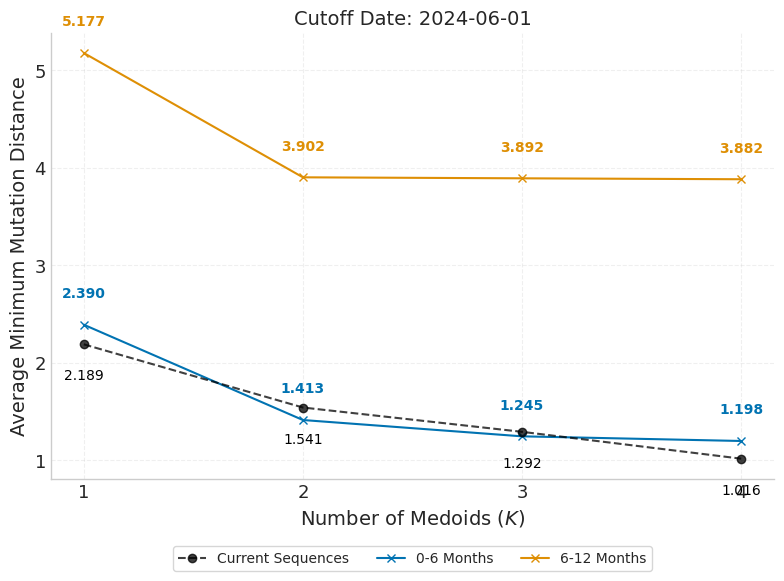

In [85]:
plot_medoid_performance(
    medoid_evaluation_results=medoid_evaluation_results,
    cutoff_date=cutoff_date
)

Distance Comparison

In [86]:
def calculate_and_print_vaccine_medoid_distances(recommended_strains, clade_to_seq, pam_results, id_to_seq):
    """
    Calculates Hamming distance between each vaccine and each individual medoid within each K set.
    Prints results in a hierarchical structured format.
    """
    
    # Helper for single-pair Hamming distance
    def get_hamming(s1, s2):
        if len(s1) != len(s2):
            return None
        return sum(c1 != c2 for c1, c2 in zip(s1, s2))

    print(f"{'='*60}")
    print(f"{'VACCINE VS MEDOID HAMMING DISTANCES':^60}")
    print(f"{'='*60}\n")

    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"Configuration: K = {k}")
        print(f"{'-'*30}")

        for m_id in medoid_ids:
            # Retrieve medoid sequence
            m_seq = id_to_seq.get(m_id)
            if m_seq is None:
                print(f"  [!] Medoid {m_id} not found in id_to_seq.")
                continue

            print(f"  Medoid ID: {m_id}")
            
            for vaccine_id in recommended_strains:
                # Retrieve vaccine sequence
                v_seq = clade_to_seq.get(vaccine_id)
                if v_seq is None:
                    print(f"    - vs {vaccine_id:.<15} [!] Not found in clade_to_seq")
                    continue
                
                dist = get_hamming(v_seq, m_seq)
                
                if dist is None:
                    print(f"    - vs {vaccine_id:.<15} Error: Length Mismatch")
                else:
                    print(f"    - vs {vaccine_id:.<15} Distance: {dist}")
            print() # Spacer between medoids
        print(f"{'='*60}\n")

# Usage Call:
calculate_and_print_vaccine_medoid_distances(
    recommended_strains= recommended_strains,
    clade_to_seq=clade_to_seq,
    pam_results=pam_results,
    id_to_seq=id_to_seq
)

            VACCINE VS MEDOID HAMMING DISTANCES             

Configuration: K = 1
------------------------------
  Medoid ID: S_419910
    - vs JN.1........... Distance: 2


Configuration: K = 2
------------------------------
  Medoid ID: S_422196
    - vs JN.1........... Distance: 3

  Medoid ID: S_426303
    - vs JN.1........... Distance: 2


Configuration: K = 3
------------------------------
  Medoid ID: S_426303
    - vs JN.1........... Distance: 2

  Medoid ID: S_427520
    - vs JN.1........... Distance: 3

  Medoid ID: S_422196
    - vs JN.1........... Distance: 3


Configuration: K = 4
------------------------------
  Medoid ID: S_413761
    - vs JN.1........... Distance: 1

  Medoid ID: S_427520
    - vs JN.1........... Distance: 3

  Medoid ID: S_422196
    - vs JN.1........... Distance: 3

  Medoid ID: S_426303
    - vs JN.1........... Distance: 2




PyR0 Fitness Score Comparisons

In [87]:
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")

Loaded 2478 PyR₀ mutation scores


In [88]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)

In [89]:
# --- Add mutation information to current sequences ---
vaccine_df = add_mutations_column(vaccine_df, clade_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
vaccine_df = add_fitness_scores_pyro(vaccine_df, mutation_score_dict_pyro)

In [90]:
def print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df):
    """
    Look up and print fitness_score_pyro for medoids and vaccines.
    Uses Sequence_ID as the key for lookup.
    """
    
    # Pre-index DataFrames for O(1) lookup performance
    # Handling cases where IDs might be missing
    fitness_map_medoids = current_seq_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()
    fitness_map_vaccines = vaccine_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()

    print(f"{'='*60}")
    print(f"{'FITNESS SCORE (PYRO) EVALUATION':^60}")
    print(f"{'='*60}\n")

    # 1. Print Vaccine Fitness Scores
    print("VACCINE STRAIN SCORES")
    print(f"{'-'*30}")
    for strain in recommended_strains:
        score = fitness_map_vaccines.get(strain, "N/A (Not Found)")
        score_val = f"{score:.5f}" if isinstance(score, float) else score
        print(f"  {strain:.<20} Score: {score_val}")
    print()

    # 2. Print Medoid Fitness Scores per K
    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"MEDOIDS FOR K = {k}")
        print(f"{'-'*30}")
        
        for m_id in medoid_ids:
            score = fitness_map_medoids.get(m_id, "N/A (Not Found)")
            score_val = f"{score:.5f}" if isinstance(score, float) else score
            print(f"  ID: {m_id:.<18} Score: {score_val}")
        print()

    print(f"{'='*60}")

print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df)

              FITNESS SCORE (PYRO) EVALUATION               

VACCINE STRAIN SCORES
------------------------------
  JN.1................ Score: 5.04679

MEDOIDS FOR K = 1
------------------------------
  ID: S_419910.......... Score: 5.26014

MEDOIDS FOR K = 2
------------------------------
  ID: S_422196.......... Score: 5.25994
  ID: S_426303.......... Score: 5.32259

MEDOIDS FOR K = 3
------------------------------
  ID: S_426303.......... Score: 5.32259
  ID: S_427520.......... Score: 5.32195
  ID: S_422196.......... Score: 5.25994

MEDOIDS FOR K = 4
------------------------------
  ID: S_413761.......... Score: 5.26078
  ID: S_427520.......... Score: 5.32195
  ID: S_422196.......... Score: 5.25994
  ID: S_426303.......... Score: 5.32259

